# Un grafo explícito con $\mu > 11/16$ que no sincroniza

**Dirección A** de la competencia: grafos densos con *trampas*, es decir, mínimos locales estrictos de
la energía de Kuramoto que no son el estado sincronizado. Este notebook construye un grafo **explícito,
no pesado y certificado** con $n = 30\,000\,004$ vértices y

$$\mu = \frac{\delta + 1}{n} = \frac{10327019}{15000002} \approx 0.688468 \;>\; \frac{11}{16} = 0.6875,$$

que tiene un equilibrio estable no sincronizado. Por lo tanto $\mu_c > 0.688468$.

| construcción | $\mu$ | $n$ | ¿grafo escrito? |
|---|---|---|---|
| Canale (k-spinning) | $\to 11/16$ por debajo (0.6874 con $n = 10^4$) | $8k$ | sí |
| O'Keeffe (arXiv 2610.21271, familia S7) | 0.6929 | $> 9\cdot 10^{84}$ | no (solo existencia) |
| **este notebook** (S7 + reticulado + blow-up circulante) | **0.688468** | $3\cdot 10^{7}$ | **sí** (unos KB) |

El camino tiene cinco pasos y el notebook los recorre en orden. Cada uno empieza por la teoría, después
explica el código (y, si es un script largo, el comando exacto y en qué máquina correrlo) y recién
después muestra los resultados.

1. **Plantilla S7** (secciones 2–3): un estado de 7 clusters en el límite de grafo grande.
2. **Fase 0, la curva** (sección 4): cuánto $\mu$ se pierde a cambio de margen de estabilidad.
3. **Fase 1, datos enteros** (secciones 5–6): redondear las densidades a grados enteros sin destruir
   el equilibrio. Es el paso difícil: el equilibrio está al lado de un pliegue y el redondeo ingenuo
   necesita $n \sim 10^9$. Con un redondeo por reticulado alcanza $n = 3\cdot 10^7$.
4. **Fase 2, el grafo** (sección 7): un blow-up circulante, con grados exactos.
5. **Fase 3, el certificado** (sección 8): aritmética de intervalos. Toda la dificultad queda en una
   matriz de $7 \times 7$.
6. **Fase 4, validación ciega** (sección 9): el Hessiano del grafo de $3\cdot 10^7$ vértices, en float64
   y sin usar la teoría del certificado.

**Colab.** Este notebook usa `src/` y `data/` del repo, que es privado. En Colab, la celda de abajo lo clona usando un token de GitHub guardado en los Secrets (ícono de la llave, nombre `GITHUB_TOKEN`, con "Notebook access" activado); en local no hace nada. Para traer cambios nuevos: `!git -C /content/investighaton-teo-optimizacion-2026 pull`.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
CARPETA_REPO = "/content/investighaton-teo-optimizacion-2026"

if EN_COLAB:
    if not os.path.exists(CARPETA_REPO):
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        !git clone -q https://{token}@github.com/Nicoyanz98/investighaton-teo-optimizacion-2026.git {CARPETA_REPO}
    %cd {CARPETA_REPO}/notebooks
    !pip install -q -r requirements.txt

In [2]:
import inspect
import sys
import time
from fractions import Fraction
from pathlib import Path

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

from src import blowup, certificado, enteros, plantillas, reticulado, validacion
from src.blowup import (adyacencia_densa, certificar_blowup, descripcion_compacta, fases_vertices,
                        hessiano_denso, hessiano_fourier, margenes_gershgorin, tabla_transporte)
from src.busqueda import sdp_interno
from src.enteros import (evaluar_enteros, fases_s7, grados_ingenuos, mu_entero, paso_grado, pulir,
                         redondeo_reticulado, tamanos_enteros, tamanos_exactos)
from src.experimentos import cargar_json, silenciar_avisos
from src.plantillas import analizar, jacobiano_fuerzas
from src.s7 import NOMBRES, esquina, patron_limite
from src.validacion import Arreglos, GrafoImplicito, lanczos

silenciar_avisos()
plt.rcParams["figure.dpi"] = 110
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]


def mostrar_codigo(*funciones):
    # Imprime el código fuente de funciones de src/ (para leerlo sin salir del notebook).
    for funcion in funciones:
        print(inspect.getsource(funcion))

## 1. El problema

**Modelo.** En un grafo $G$ con $n$ vértices y adyacencia $W$, el modelo de Kuramoto homogéneo es
$$\dot\theta_u = \sum_v W_{uv}\,\sin(\theta_v - \theta_u),$$
el flujo gradiente de la energía $E(\theta) = \sum_{uv \in E} \big(1 - \cos(\theta_u - \theta_v)\big)$.
El estado sincronizado ($\theta$ constante) es el mínimo global. Un **equilibrio** cumple $\dot\theta = 0$,
y es un **mínimo local estricto** si el Hessiano
$$H_{uv} = -W_{uv}\cos(\theta_u - \theta_v)\ (u \ne v), \qquad H_{uu} = \sum_v W_{uv}\cos(\theta_u - \theta_v)$$
es semidefinido positivo con núcleo igual a la rotación global ($H\mathbf 1 = 0$). Un mínimo estricto
no sincronizado es una trampa: la dinámica que arranca cerca se queda ahí.

**El umbral.** Medimos la densidad con $\mu = (\delta + 1)/n$, donde $\delta$ es el grado mínimo (el
grafo completo tiene $\mu = 1$). $\mu_c$ es el ínfimo de los $\mu$ que garantizan sincronización global:
todo grafo con densidad mayor que $\mu_c$ sincroniza desde casi toda condición inicial. Para mostrar
$\mu_c > \mu_0$ basta **un** grafo con $\mu > \mu_0$ que tenga una trampa.

**Lo conocido.**
- Canale construye grafos explícitos (k-spinning, $n = 8k$) con trampas cuya densidad tiende a $11/16$
  por debajo: con $n = 10^4$ da 0.6874. Eso da $\mu_c \ge 11/16$.
- O'Keeffe (arXiv 2610.21271) prueba $\mu_c \ge 0.6929$ con la familia S7 (sección 3). El grafo existe,
  pero tiene $n > 9\cdot 10^{84}$ y nunca se escribe:
  - racionaliza un miembro de la familia a $6\cdot 10^{-19}$ de la neutralidad, con denominador
    $D \approx 3\cdot 10^{42}$;
  - y lo convierte en grafo con un blow-up aleatorio de $n = D^2 \ell$ vértices.

**Objetivo de este notebook:** un grafo escrito, no pesado, con $\mu > 11/16$ y una trampa
**certificada** (no solo numérica), con $n$ lo más chico posible.

## 2. Plantillas: estados de clusters en el límite de grafo grande

Una **plantilla** es un estado en el que los vértices se agrupan en $m$ clusters, cada uno con una
sola fase:
- $x_a$: fracción de vértices en el cluster $a$ ($\sum_a x_a = 1$);
- $\varphi_a$: fase del cluster $a$;
- $P_{ab}$: densidad de links entre los clusters $a$ y $b$ ($P_{aa} = 1$: cada cluster es un clique).

Si cada vértice de $a$ tiene exactamente $P_{ab}\, n x_b$ vecinos en $b$ (ver la sección 7 para cómo
lograrlo), todas las cantidades del grafo se escriben con $(x, \varphi, P)$:

- **Grado:** un vértice de $a$ tiene grado $\approx n\, d_a$ con $d_a = \sum_b P_{ab} x_b$, así que
  $\mu(T) = \min_a d_a$.
- **Equilibrio:** $\dot\theta_u = -n F_a$ para $u$ en $a$, con
  $F_a = \sum_{b} P_{ab} x_b \sin(\varphi_a - \varphi_b)$. Hay equilibrio si $F = 0$.
- **Estabilidad contra separar un vértice** (modos dentro de un cluster): el Hessiano en esas
  direcciones es $\approx n c_a$ con $c_a = \sum_b P_{ab} x_b \cos(\varphi_a - \varphi_b)$. Hace falta
  $c_a > 0$.
- **Estabilidad de los modos de cluster** (mover cada cluster entero una cantidad $y_a$):
  $\theta^\top H \theta = n^2 L(y)$ con
  $$L(y) = \sum_{a<b} x_a x_b P_{ab}\cos(\varphi_a - \varphi_b)\,(y_a - y_b)^2 .$$
  Hace falta $L(y) > 0$ para todo $y$ que no sea constante (una rotación global).

Una plantilla es **estricta** si cumple las tres condiciones. Las funciones de `src/plantillas.py`
calculan $F$, $c$ y la matriz de $L$. Reciben un parámetro `lib`, que puede ser `numpy` (float),
`mpmath` (alta precisión) o `mpmath.iv` (intervalos): el mismo código sirve para explorar, para
redondear en alta precisión y para el certificado riguroso.

In [3]:
mostrar_codigo(plantillas.fuerzas, plantillas.splitting, plantillas.matriz_clusters)

def fuerzas(x, phi, P, lib=np):
    """F_a = Σ_{b≠a} P_ab x_b sin(φ_a − φ_b); el equilibrio es F = 0."""
    m = len(x)
    F = []
    for a in range(m):
        total = 0
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.sin(phi[a] - phi[b])
        F.append(total)
    return F

def splitting(x, phi, P, lib=np):
    """c_a = Σ_b P_ab x_b cos(φ_a − φ_b): cuánto tira el resto hacia el cluster a si un oscilador se separa."""
    m = len(x)
    c = []
    for a in range(m):
        total = P[a][a] * x[a]
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.cos(phi[a] - phi[b])
        c.append(total)
    return c

def matriz_clusters(x, phi, P, lib=np):
    """Matriz de L(y): Laplaciano con pesos x_a x_b P_ab cos(φ_a − φ_b), como lista de listas."""
    m = len(x)
    L = []
    for a in range(m):
        fila = [0] * m
        for b in range(m):
            if b != a:
                fi

## 3. La familia S7

**La base C4.** Cuatro sectores en las fases $0, \pi/2, \pi, 3\pi/2$, cada uno unido completo con los
dos vecinos y sin links con el opuesto. S7 la deforma así:
- los sectores A (fase 0), B ($\pi/2$) y C ($\pi$) tienen tamaño $2a$ y se parten en dos mitades
  ($A_m, A_p$, etc.), corridas $\pm h\,s$ respecto de la fase del sector;
- el sector W ($3\pi/2$) tiene tamaño $1 - 6a$ y no se parte;
- los clusters quedan en el orden $(A_m, A_p, B_m, B_p, C_m, C_p, W)$, con desplazamientos
  $s = (-1, 1, -w, w, -1, 1, 0)$.

**El patrón límite** (cuando $h \to 0$):
- entre sectores vecinos todo es completo, salvo los pares cruzados ($A_m$–$B_p$, $A_p$–$B_m$, y lo mismo
  entre B y C), que tienen densidad $q$;
- A–C y B–W no tienen links.

Con eso los grados límite son:
$$d_{A_m} = 2a + (1+q)a + (1-6a) = \frac{4 + 2q}{7 + q}\ \text{ con } a = \frac{1}{7+q},\qquad
d_{B_m} = 2a + 2(1+q)a = \frac{4+2q}{7+q},\qquad d_W = 1 - 2a.$$
Por lo tanto $\mu_0(q) = (4+2q)/(7+q)$, que crece con $q$.

**Hasta dónde puede crecer $q$.** Para $h \to 0$ los modos de cluster de S7 tienen autovalores de orden
$h^2$. Hay un punto $(q^*, w^*)$, la "esquina" (raíz de dos polinomios del Apéndice A de O'Keeffe), en
el que dos de esos modos (los "dipolos") son exactamente neutros. Para $q$ un poco menor que $q^*$ la
plantilla es estricta, y $\mu \to \mu_0(q^*) \approx 0.6929$. Ese es el valor de O'Keeffe.

In [4]:
q_estrella, w_estrella, mu_cero = esquina(30)
print(f"q* = {mp.nstr(q_estrella, 12)}   w* = {mp.nstr(w_estrella, 12)}   μ0 = (4 + 2q*)/(7 + q*) = {mp.nstr(mu_cero, 12)}")
print()
print("patrón límite P (q = q*):")
print("       " + "".join(f"{nombre:>7s}" for nombre in NOMBRES))
for nombre, fila in zip(NOMBRES, patron_limite(q_estrella)):
    print(f"{nombre:>7s}" + "".join(f"{float(v):7.3f}" for v in fila))

q* = 0.650569166945   w* = 1.39827813402   μ0 = (4 + 2q*)/(7 + q*) = 0.69290770637

patrón límite P (q = q*):
            Am     Ap     Bm     Bp     Cm     Cp      W
     Am  1.000  1.000  1.000  0.651  0.000  0.000  1.000
     Ap  1.000  1.000  0.651  1.000  0.000  0.000  1.000
     Bm  1.000  0.651  1.000  1.000  1.000  0.651  0.000
     Bp  0.651  1.000  1.000  1.000  0.651  1.000  0.000
     Cm  0.000  0.000  1.000  0.651  1.000  1.000  1.000
     Cp  0.000  0.000  0.651  1.000  1.000  1.000  1.000
      W  1.000  1.000  0.000  0.000  1.000  1.000  1.000


**El costo de la cercanía a la esquina.** Cerca de $(q^*, w^*)$ el margen de estabilidad de los modos de
cluster es diminuto (O'Keeffe trabaja a $6\cdot 10^{-19}$ de la neutralidad), y eso es lo que encarece
pasar a un grafo con $n$ finito (sección 5). Para tener un grafo chico hay que **resignar algo de
$\mu$ a cambio de margen**. Por eso no usamos las densidades perturbativas de O'Keeffe sino las óptimas
para un margen dado:

- **SDP interno** (`src/busqueda.py: sdp_interno`). Con $x$ y $\varphi$ fijos, maximizar $\min_a d_a$
  sobre las densidades $P$ es un problema convexo:
  - $0 \le P \le 1$ simétrica, $P_{aa} = 1$, $P_{ab} = 0$ en los pares sin links (A–C, B–W);
  - $F(P) = 0$ y $c(P) \ge 10^{-3}$: son lineales en $P$;
  - $Q^\top L(P)\, Q / h^2 \succeq \varepsilon I$, con $Q$ una base de $\mathbf 1^\perp$: es lineal en $P$,
    así que es una restricción semidefinida.

  Se divide por $h^2$ porque los modos de cluster son $O(h^2)$, y $\varepsilon$ es el **margen** pedido.
- **Problema externo** (`src/enteros.py: optimizar_s7`): Nelder–Mead sobre los desplazamientos $s$ de
  las seis mitades. Los tamaños se fijan racionales desde el principio, $x = (k_A, \dots, k_A, k_W)/K$,
  porque así después no hay que redondearlos. Con $(k_A, k_W) = (3, 5)$ queda
  $K = 6\cdot 3 + 5 = 23$, y $k_W/k_A = 1.67$ está cerca del óptimo $(1 - 6a)/a = 1 + q^* \approx 1.65$.

In [5]:
mostrar_codigo(sdp_interno)

def sdp_interno(x, phi, escala=1.0, margen=1e-6, margen_c=1e-3, prohibidos=None, solver="CLARABEL"):
    """Mayor μ sobre las densidades P con x y φ fijos. Devuelve (μ, P) o (None, None) si es infactible."""
    m = len(x)
    diferencias = phi[:, None] - phi[None, :]
    senos = np.sin(diferencias)
    cosenos = np.cos(diferencias)
    pesos_L = np.outer(x, x) * cosenos
    np.fill_diagonal(pesos_L, 0)

    P = cp.Variable((m, m), symmetric=True)
    t = cp.Variable()
    K = cp.multiply(P, pesos_L)
    L = cp.diag(cp.sum(K, axis=1)) - K
    Q = base_perpendicular(m)
    restricciones = [
        P >= 0,
        P <= 1,
        cp.diag(P) == 1,
        P @ x >= t,
        cp.multiply(P, senos) @ x == 0,
        cp.multiply(P, cosenos) @ x >= margen_c,
        (Q.T @ L @ Q) / escala >> margen * np.eye(m - 1),
    ]
    if prohibidos is not None:
        restricciones.append(cp.multiply(P, prohibidos.astype(float)) == 0)
    problema = cp.Problem(cp.Maximize(t), restricciones)
    try:


**La plantilla que usamos** tiene $h = 0.03$, $\varepsilon = 10^{-3}$ y tamaños $(3, 5)$. Sale de la
Fase 0 (sección 4) y está guardada en `data/s7_curva.json`, con sus desplazamientos `s` y densidades `P`.
Acá la cargamos y medimos con `analizar` su $\mu$, el residuo del equilibrio, $\min c$ y los autovalores
de $L$ (normalizados como $X^{-1/2} L X^{-1/2}$, sin el 0 de la rotación). También calculamos los
valores singulares del Jacobiano del equilibrio $J = \partial F/\partial\varphi$ (con $\varphi_0$ fijo),
que van a ser centrales en la sección 5.

In [6]:
curva = cargar_json("s7_curva.json")


def fila_curva(h, margen, k=(3, 5)):
    # Fila de data/s7_curva.json con esos parámetros.
    for fila in curva:
        if fila["h"] == h and fila["margen"] == margen and tuple(fila["k"]) == tuple(k):
            return fila
    raise KeyError((h, margen, k))


H_PLANTILLA = 0.03
plantilla = fila_curva(H_PLANTILLA, 1e-3)
k_s7 = [3] * 6 + [5]
x_plantilla = np.array(k_s7) / sum(k_s7)
phi_plantilla = fases_s7(H_PLANTILLA, np.array(plantilla["s"]))
P_plantilla = np.array(plantilla["P"])

reporte = analizar(x_plantilla, phi_plantilla, P_plantilla)
print(f"μ = {reporte['mu']:.6f}   max|F| = {reporte['max|F|']:.1e}   min c = {reporte['min c']:.4f}")
print("autovalores de L:", "  ".join(f"{v:.2e}" for v in reporte["autovalores L"]))
singulares = np.linalg.svd(np.array(jacobiano_fuerzas(x_plantilla, phi_plantilla, P_plantilla)), compute_uv=False)
print("valores singulares de J:", "  ".join(f"{v:.2e}" for v in singulares))

μ = 0.688469   max|F| = 1.5e-11   min c = 0.2179
autovalores de L: 9.00e-07  9.00e-07  1.16e-04  3.40e-02  3.41e-02  3.41e-02
valores singulares de J: 2.61e-01  2.61e-01  1.29e-01  5.95e-04  5.29e-06  2.34e-06


- **μ = 0.6885:** está entre $11/16 = 0.6875$ y $\mu_0 = 0.6929$.
- **max|F| ≠ 0:** el SDP no da un equilibrio exacto, sino uno con error del orden de la tolerancia
  del solver. En la sección 5 se corrige.
- **Valores singulares de J:** hay **tres** chicos ($6\cdot10^{-4}$, $5\cdot10^{-6}$ y $2\cdot10^{-6}$);
  los demás son $\gtrsim 0.1$. Son los modos casi neutros heredados de C4, y van a determinar el tamaño
  del grafo.

## 4. Fase 0: cuánto $\mu$ cuesta el margen

**Qué calcula** `scripts/curva_s7.py`. Para cada $h \in \{0.005, 0.01, 0.02, 0.03, 0.05\}$, cada margen
$\varepsilon \in \{10^{-5}, \dots, 10^{-2}\}$ y cada par de tamaños $(3,5), (11,18), (20,33)$:
1. optimiza S7 (`optimizar_s7`: Nelder–Mead en $s$ con el SDP interno adentro);
2. guarda $\mu$, los autovalores normalizados de $L$, $\min c$ y la condición de $J$;
3. busca en una grilla el menor $n$ con el que el **redondeo ingenuo** de los grados (sección 5) sigue
   dando un equilibrio estricto, como línea de base.

Cada punto es independiente, así que se reparten entre procesos (`correr_en_paralelo`).

**Cómo correrlo** (CPU; en el server con 12 núcleos tarda unos minutos, ~80 min de CPU en total):
```bash
OMP_NUM_THREADS=1 .venv/bin/python scripts/curva_s7.py --procesos 12
```
`OMP_NUM_THREADS=1` evita que cada proceso abra sus propios hilos de BLAS. La salida es
`data/s7_curva.json`, una fila por punto.

120 puntos, 79 min de CPU en total


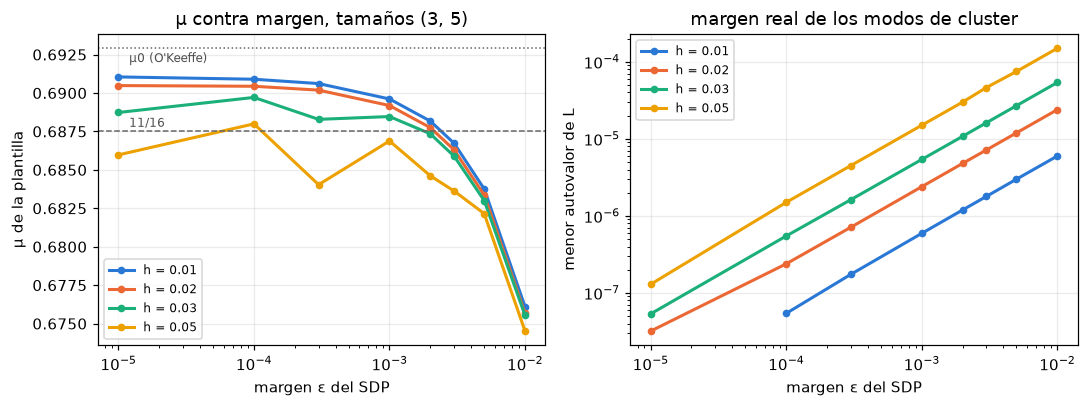

In [7]:
print(f"{len(curva)} puntos, {sum(f.get('segundos', 0) for f in curva) / 60:.0f} min de CPU en total")

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
for color, h in zip(COLORES, [0.01, 0.02, 0.03, 0.05]):
    filas = sorted([f for f in curva if f["h"] == h and tuple(f["k"]) == (3, 5)], key=lambda f: f["margen"])
    margenes = [f["margen"] for f in filas]
    ejes[0].plot(margenes, [f["mu"] for f in filas], "o-", color=color, lw=2, ms=4, label=f"h = {h}")
    positivos = [f for f in filas if f["autovalores"][0] > 0]     # con ε muy chico el SDP puede dar ≤ 0 (ruido)
    ejes[1].plot([f["margen"] for f in positivos], [f["autovalores"][0] for f in positivos], "o-", color=color,
                 lw=2, ms=4, label=f"h = {h}")
ejes[0].axhline(11 / 16, color="0.4", lw=1, ls="--")
ejes[0].text(1.2e-5, 11 / 16 + 3e-4, "11/16", color="0.3", fontsize=8)
ejes[0].axhline(float(mu_cero), color="0.4", lw=1, ls=":")
ejes[0].text(1.2e-5, float(mu_cero) - 9e-4, "μ0 (O'Keeffe)", color="0.3", fontsize=8)
ejes[0].set(xscale="log", xlabel="margen ε del SDP", ylabel="μ de la plantilla", title="μ contra margen, tamaños (3, 5)")
ejes[1].set(xscale="log", yscale="log", xlabel="margen ε del SDP", ylabel="menor autovalor de L",
            title="margen real de los modos de cluster")
for eje in ejes:
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- $\mu$ baja al subir el margen $\varepsilon$, y baja más rápido cuanto más grande es $h$. La curva es
  ruidosa porque Nelder–Mead no siempre encuentra el óptimo en $s$ (sobre todo con $h = 0.05$).
- El menor autovalor de $L$ crece como $\sim \varepsilon h^2$.
- Hay una ventana con $\mu > 11/16$ y margen apreciable. La plantilla elegida ($h = 0.03$,
  $\varepsilon = 10^{-3}$) tiene $\mu = 0.6885$.

## 5. De la plantilla a datos enteros, y por qué es difícil

**Datos enteros.** Un grafo concreto se describe con:
- tamaños $n_a = k_a g$ (6 mitades de $3g$ vértices y W de $5g$, así que $n = 23g$);
- grados $d_{ab}$: cuántos vecinos tiene **cada** vértice de $a$ en $b$.

Hay dos restricciones:
- **contar los links entre $a$ y $b$ desde los dos lados** da $n_a d_{ab} = n_b d_{ba}$;
- cada cluster es un clique: $d_{aa} = n_a - 1$.

Para que $n_a d_{ab} = n_b d_{ba}$ tenga solución, $d_{ab}$ tiene que ser múltiplo de
$k_b/\mathrm{mcd}(k_a, k_b)$ (`paso_grado`). La plantilla del grafo es $x_a = n_a/n$,
$P_{ab} = d_{ab}/n_b$, y $\mu = (\delta + 1)/n$ con $\delta = \min_a \sum_b d_{ab}$.

**Primero se pule la plantilla** (`pulir`): el SDP deja $F \approx 10^{-9}$, y por lo que sigue eso
solo ya movería mucho las fases. Como $F$ es lineal en $P$, se corrige $P$ con el cambio de mínima
norma que da $F(\varphi) = 0$ exacto (mínimos cuadrados en alta precisión, solo en los pares con
$0 < P_{ab} < 1$).

**El redondeo ingenuo** (`grados_ingenuos`) toma $d_{ab}$ = el múltiplo permitido más cercano a
$P_{ab} n_b$. El error en las densidades es $\sim 1/n$.

**El pliegue.** $J$ tiene tres valores singulares $\sigma_k$ muy chicos (sección 3).
- **Forma normal.** En la dirección blanda $k$, el equilibrio de los datos perturbados es raíz de
  $$\sigma_k\, y + \tfrac{c}{2}\, y^2 + \rho_k = 0,$$
  donde $\rho_k$ es el residuo de esa ecuación. Es la forma normal de una silla-nodo: el mínimo
  estricto vive al lado de un pliegue.
- **Existencia y estabilidad.** Hay solución solo si $2c\rho_k \le \sigma_k^2$, y su estabilidad es
  $\sqrt{\sigma_k^2 - 2c\rho_k}$.
- **Costo del redondeo ingenuo.** Como $\rho_k \sim 1/n$, hace falta $n \gtrsim c/\sigma_k^2$. La
  constante depende de cuánto pesa cada error de redondeo en la dirección blanda, así que la escala
  exacta se mide: para esta plantilla el redondeo ingenuo necesita $n \approx 10^9$.
- **Si el redondeo pasa el pliegue, el equilibrio desaparece:** Newton se estanca o las fases saltan
  lejos de las de S7.

`evaluar_enteros` resuelve el equilibrio exacto de los datos enteros (Newton en mpmath, 40 dígitos) y
mira si es estricto: $L \succ 0$, $c > 0$, $|F| < 10^{-20}$ y fases a menos de $h/4$ de las de la
plantilla. Lo probamos con el redondeo ingenuo para $n = 3\cdot 10^7$ y $n = 10^9$.

In [8]:
mostrar_codigo(paso_grado, grados_ingenuos)

def paso_grado(k, a, b):
    """d_ab tiene que ser múltiplo de k_b/mcd(k_a, k_b) para que n_a d_ab = n_b d_ba."""
    return int(k[b]) // gcd(int(k[a]), int(k[b]))

def grados_ingenuos(x, P, k, g):
    """Redondea P_ab·n_b al múltiplo permitido más cercano (para a < b) y completa por simetría."""
    m = len(k)
    n_a = tamanos_enteros(k, g)
    d = [[0] * m for _ in range(m)]
    for a in range(m):
        d[a][a] = n_a[a] - 1
        for b in range(a + 1, m):
            paso = paso_grado(k, a, b)
            j = int(mp.nint(P[a][b] * n_a[b] / paso))
            j = max(0, min(j, n_a[b] // paso))
            d[a][b] = j * paso
            d[b][a] = d[a][b] * n_a[a] // n_a[b]
    return d



In [9]:
x_exacto, phi_pulida, P_pulida = pulir(tamanos_exactos(k_s7), phi_plantilla, P_plantilla)

for n_objetivo in [3e7, 1e9]:
    g = int(round(n_objetivo / sum(k_s7)))
    d = grados_ingenuos(x_exacto, P_pulida, k_s7, g)
    evaluacion = evaluar_enteros(k_s7, g, d, phi_pulida, H_PLANTILLA)
    print(f"n = {sum(k_s7) * g:.3e}  redondeo ingenuo: estricto {evaluacion['ok']}"
          f"   menor autovalor de L = {evaluacion['menor autovalor']:.2e}"
          f"   movimiento de fases = {evaluacion['movimiento fases']:.1e}")

n = 3.000e+07  redondeo ingenuo: estricto False   menor autovalor de L = -3.05e-03   movimiento de fases = 9.9e-03
n = 1.000e+09  redondeo ingenuo: estricto True   menor autovalor de L = 4.06e-06   movimiento de fases = 9.2e-05


Con $n = 3\cdot 10^7$ el redondeo ingenuo da un equilibrio **inestable** (autovalor negativo de $L$).
Con $n = 10^9$ funciona.

## 6. Fase 1: redondeo por reticulado

**Idea.** El redondeo ingenuo elige cada $d_{ab}$ por separado. Pero hay 13 pares con densidad
intermedia ($0 < P_{ab} < 1$), es decir 13 enteros libres, y solo 3 ecuaciones blandas que hay que
cuidar. Se pueden elegir los 13 enteros **en conjunto** para que el residuo blando quede mucho más
chico que $1/n$.

**Reducción de Lyapunov–Schmidt** (`base_blanda`, `residuo_blando`). En la plantilla se descompone
$J = U S V^\top$.
- Las direcciones rígidas (valores singulares grandes) están bien condicionadas: se resuelven
  exactamente por Newton, $U_r^\top F(\varphi^* + V_r z) = 0$.
- Queda el **residuo blando** $g = U_b^\top F$, de 3 componentes. Está bien definido aunque no haya
  equilibrio, y es casi lineal en los grados.

**Newton entero** (`corregir_grados`). En cada paso:
- se calcula $g$ y su derivada respecto de los 13 grados libres (diferencias finitas en alta
  precisión);
- se busca $u \in \mathbb Z^{13}$ con $\mathrm{d}g \cdot u \approx -g$, midiendo cada componente en
  unidades de su tolerancia $\sigma_k^2$ (la distancia al pliegue);
- además $u$ tiene que ser chico (radio $\sim 3$–$100$), para no mover las densidades y no romper las
  ecuaciones rígidas.

**El problema entero es un problema de vector más cercano en un reticulado** (`src/reticulado.py`).
- **Encaje de Kannan:** el reticulado tiene filas $(e_i/r,\ \text{peso}\cdot A_{:,i})$, donde $A$ son las
  formas lineales y $r$ el radio.
- Un vector del reticulado cerca de $(\text{objetivo}/r,\ \text{peso}\cdot A\,\text{objetivo})$ es un
  entero cerca del objetivo **y** con las formas casi anuladas.
- Se reduce la base con **LLL** y se aproxima el vector más cercano con el **plano más cercano de Babai**.

Al final, `redondeo_reticulado` evalúa cada candidato en exacto y se queda con el mejor.

In [10]:
mostrar_codigo(reticulado.enteros_cercanos, enteros.corregir_grados)

def enteros_cercanos(formas, objetivo, radio, peso=1e3):
    """u ∈ Z^m con |u − objetivo| del orden de radio y formas·(u − objetivo) ≈ 0.

    Encaje de Kannan: el reticulado tiene filas (e_i/radio, peso·formas[:, i]). Las formas se escalan
    todas por el mismo factor (máximo 1), así que el que llama decide cuánto pesa cada una.
    """
    formas = np.asarray(formas, dtype=float)
    formas = formas / max(np.abs(formas).max(), 1e-300)
    m = formas.shape[1]
    factor = peso * radio
    B = np.hstack([np.eye(m) / radio, factor * formas.T])
    objetivo = np.asarray(objetivo, dtype=float)
    vector_objetivo = np.concatenate([objetivo / radio, factor * formas @ objetivo])
    reducida = lll(B)
    coeficientes = babai(reducida, vector_objetivo)
    return np.round((coeficientes @ reducida)[:m] * radio)

def corregir_grados(d, k, g, pares, residuo, derivada, radio, tolerancias):
    """Un paso de Newton entero: grados cuyo cambio anula (en lo posible) el residuo blando.

    Cada co

**El script** `scripts/s7_entero.py` corre, para tres plantillas ($h = 0.01, 0.02, 0.03$, todas con
$\varepsilon = 10^{-3}$ y tamaños $(3,5)$) y una grilla $n \in \{10^6, 3\cdot10^6, \dots, 10^9\}$:
- el pulido;
- el redondeo ingenuo;
- el redondeo por reticulado.

Guarda si cada equilibrio exacto es estricto, el $\mu$ exacto, los grados y las fases.

**Cómo correrlo** (CPU, unos 4 min de CPU en total):
```bash
OMP_NUM_THREADS=1 .venv/bin/python scripts/s7_entero.py --procesos 12    # server
.venv/bin/python scripts/s7_entero.py --procesos 8                       # local
```
Salida: `data/s7_enteros.json`.

Antes de ver la tabla, corremos acá el redondeo por reticulado para el mismo caso de la sección 5
($h = 0.03$, $n = 3\cdot 10^7$). Tarda unos segundos.

In [11]:
g_chico = int(round(3e7 / sum(k_s7)))
inicio = time.time()
d_reticulado, evaluacion = redondeo_reticulado(x_exacto, P_pulida, phi_pulida, H_PLANTILLA, k_s7, g_chico)
print(f"n = {sum(k_s7) * g_chico}  reticulado: estricto {evaluacion['ok']}"
      f"   menor autovalor de L = {evaluacion['menor autovalor']:.2e}   ({time.time() - inicio:.1f} s)")
print(f"μ = {mu_entero(k_s7, g_chico, d_reticulado)} ≈ {float(mu_entero(k_s7, g_chico, d_reticulado)):.6f}")
d_ingenuo = grados_ingenuos(x_exacto, P_pulida, k_s7, g_chico)
print("cambios respecto del ingenuo (en múltiplos del paso permitido):")
for a in range(7):
    for b in range(a + 1, 7):
        if d_reticulado[a][b] != d_ingenuo[a][b]:
            cambio = (d_reticulado[a][b] - d_ingenuo[a][b]) // paso_grado(k_s7, a, b)
            print(f"   {NOMBRES[a]}–{NOMBRES[b]}: {cambio:+d}")

n = 30000004  reticulado: estricto True   menor autovalor de L = 5.25e-06   (2.8 s)
μ = 10327019/15000002 ≈ 0.688468
cambios respecto del ingenuo (en múltiplos del paso permitido):
   Am–Bp: -14
   Am–W: +12
   Ap–Bm: +11
   Ap–Bp: +7
   Ap–W: -10
   Bm–Cm: +20
   Bm–Cp: +2
   Bp–Cm: -19
   Cm–W: +1


Bastan cambios de unas pocas unidades en algunos grados, de un total de $\sim 10^7$, para que el
equilibrio pase de inestable a estricto. La tabla completa de la Fase 1:

In [12]:
filas_enteras = cargar_json("s7_enteros.json")
print(f"{'h':>5s} {'n':>12s} {'ingenuo':>9s} {'reticulado':>11s} {'λ_min(L)':>11s} {'μ':>10s}")
for r in filas_enteras:
    mu_texto = f"{r['mu']:.6f}" if r["reticulado_ok"] else "—"
    print(f"{r['h']:5.2f} {r['n']:12.3e} {str(r['ingenuo_ok']):>9s} {str(r['reticulado_ok']):>11s}"
          f" {r['menor_autovalor']:11.2e} {mu_texto:>10s}")

    h            n   ingenuo  reticulado    λ_min(L)          μ
 0.01    1.000e+06     False       False   -4.49e-05          —
 0.01    3.000e+06     False       False   -4.61e-04          —
 0.01    1.000e+07     False       False   -3.49e-05          —
 0.01    3.000e+07     False       False   -8.90e-06          —
 0.01    1.000e+08     False       False   -7.57e-06          —
 0.01    3.000e+08     False       False   -3.35e-06          —
 0.01    1.000e+09     False       False   -8.04e-08          —
 0.02    1.000e+06     False       False   -2.75e-04          —
 0.02    3.000e+06     False       False   -5.96e-05          —
 0.02    1.000e+07     False       False   -1.12e-05          —
 0.02    3.000e+07     False       False   -1.25e-06          —
 0.02    1.000e+08     False        True    1.11e-06   0.689183
 0.02    3.000e+08     False        True    2.03e-06   0.689184
 0.02    1.000e+09     False        True    2.38e-06   0.689184
 0.03    1.000e+06     False       False

**Lectura.**
- El reticulado baja el $n$ necesario en uno o dos órdenes de magnitud:
  - $h = 0.03$: de $10^9$ a $3\cdot10^7$;
  - $h = 0.02$: de más de $10^9$ a $10^8$, con $\mu = 0.689183$.
- $h = 0.01$ tiene más $\mu$ pero menos margen, y no alcanza ni con $n = 10^9$.
- **Escala (heurística):** el ingenuo necesita $n \sim \sigma^{-2}$, y el reticulado con 13 enteros y
  3 restricciones $n \sim \sigma^{-1.23}$. Con más enteros libres por restricción se debería acercar a
  $\sigma^{-1}$. Esa es la idea del "camino B" (sección 10).

## 7. Fase 2: el grafo, un blow-up circulante

Falta un grafo en el que **cada** vértice de $a$ tenga **exactamente** $d_{ab}$ vecinos en $b$. Con eso
las fases de los clusters son un equilibrio exacto del grafo, porque la velocidad de un vértice de $a$
es $-nF_a = 0$. Usamos un blow-up circulante, que generaliza el k-spinning de Canale
(`src/blowup.py`):

- **Vértices:** el cluster $a$ tiene $k_a$ bloques y cada bloque es una copia de $\mathbb Z_g$. El
  vértice es $(a, i, v)$, con $i < k_a$ y $v \in \mathbb Z_g$.
- **Dentro de un cluster:** clique.
- **Entre clusters $a < b$:** $(a, i, v) \sim (b, j, v + s \bmod g)$ para $s \in \{0, \dots, t_{ij} - 1\}$
  (un intervalo, como en Canale).
- **Grados:** un vértice $(a, i, \cdot)$ tiene $\sum_j t_{ij}$ vecinos en $b$, y un vértice
  $(b, j, \cdot)$ tiene $\sum_i t_{ij}$ vecinos en $a$. Entonces hace falta una tabla $t$ de
  $k_a \times k_b$ con filas que sumen $d_{ab}$, columnas que sumen $d_{ba}$ y entradas en $[0, g]$.
  Es un problema de transporte.

**Solución explícita del transporte** (`tabla_transporte`):
- todas las entradas valen $\text{base}$ o $\text{base} + 1$;
- en la fila $i$, los "+1" van en las columnas $i e, \dots, ie + e - 1 \pmod{k_b}$, con
  $e = d_{ab} - k_b\,\text{base}$;
- recorridas en orden, las filas cubren las columnas de forma cíclica, así que cada columna recibe la
  misma cantidad de "+1".

No hace falta que $g$ sea múltiplo de nada. Ahí se ahorra el $D^2$ de O'Keeffe: el grafo tiene
$n = 23 g$ vértices, con $g$ libre.

**Lo que se publica** (`descripcion_compacta`): $k$, $g$, los grados, las tablas y las fases. Son unos
pocos KB, y con eso cualquiera reconstruye el grafo.

In [13]:
mostrar_codigo(tabla_transporte)

def tabla_transporte(d_ab, k_a, k_b, g):
    """Tabla t (k_a × k_b) con filas d_ab, columnas d_ba = k_a d_ab/k_b y entradas en {base, base + 1} ⊂ [0, g].

    Los "+1" de la fila i van en las columnas i·e, …, i·e + e − 1 (mod k_b), con e = d_ab − k_b·base:
    recorridas en orden, las filas cubren las columnas de forma cíclica y cada una recibe los mismos.
    """
    total = k_a * d_ab
    assert total % k_b == 0, "tiene que valer k_a d_ab = k_b d_ba"
    assert 0 <= d_ab <= k_b * g
    base = total // (k_a * k_b)
    extra_fila = d_ab - k_b * base
    t = [[base] * k_b for _ in range(k_a)]
    for i in range(k_a):
        for desplazamiento in range(extra_fila):
            t[i][(i * extra_fila + desplazamiento) % k_b] += 1
    return t



Un ejemplo chico para verlo: $k = (1, 2, 3)$, $g = 5$ ($n = 30$), con grados elegidos a mano. Se arma
la adyacencia densa (`adyacencia_densa`), se verifica que cada vértice tiene exactamente los grados
pedidos y se dibuja la matriz.

grados exactos en los 30 vértices; tablas: {(0, 1): [[2, 2]], (0, 2): [[2, 2, 2]], (1, 2): [[3, 3, 3], [3, 3, 3]]}


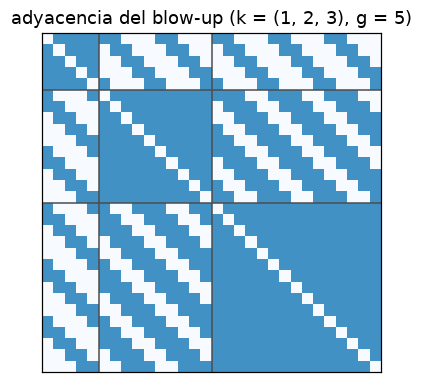

In [14]:
k_ejemplo = [1, 2, 3]
g_ejemplo = 5
d_ejemplo = [[4, 4, 6], [2, 9, 9], [2, 6, 14]]     # n_a d_ab = n_b d_ba con n = (5, 10, 15)
W_ejemplo = adyacencia_densa(k_ejemplo, g_ejemplo, d_ejemplo)
inicios = blowup.desplazamientos_cluster(k_ejemplo, g_ejemplo)
tamanos = tamanos_enteros(k_ejemplo, g_ejemplo)
for a in range(3):
    for b in range(3):
        cuentas = W_ejemplo[inicios[a]: inicios[a] + tamanos[a], inicios[b]: inicios[b] + tamanos[b]].sum(axis=1)
        assert (cuentas == d_ejemplo[a][b]).all()
print("grados exactos en los 30 vértices; tablas:", blowup.tablas_bloques(k_ejemplo, g_ejemplo, d_ejemplo))

fig, eje = plt.subplots(figsize=(4, 4))
eje.imshow(W_ejemplo, cmap="Blues", vmin=0, vmax=1.6)
for corte in inicios[1:]:
    eje.axhline(corte - 0.5, color="0.3", lw=1)
    eje.axvline(corte - 0.5, color="0.3", lw=1)
eje.set(title="adyacencia del blow-up (k = (1, 2, 3), g = 5)", xticks=[], yticks=[])
plt.show()

Las diagonales que se ven fuera de los bloques de cada cluster son los intervalos de desplazamientos
(matrices circulantes). En el grafo real, una tabla con "+1" (entradas $\text{base}$ y $\text{base}+1$):

In [15]:
grafos = cargar_json("grafos_s7.json")
grafo_chico = min([f for f in grafos if f["redondeo"] == "reticulado"], key=lambda f: f["grafo"]["n"])
descripcion = grafo_chico["grafo"]
print(f"n = {descripcion['n']}, g = {descripcion['g']}, k = {descripcion['k']}")
for clave, tabla in descripcion["tablas"].items():
    if len(np.unique(tabla)) > 1:
        a, b = (int(c) for c in clave.split(","))
        print(f"{NOMBRES[a]}–{NOMBRES[b]}: d = {descripcion['grados'][a][b]} (filas), {descripcion['grados'][b][a]} (columnas)")
        print(np.array(tabla))
        break

n = 30000004, g = 1304348, k = [3, 3, 3, 3, 3, 3, 5]
Am–Bp: d = 2402234 (filas), 2402234 (columnas)
[[800745 800745 800744]
 [800745 800744 800745]
 [800744 800745 800745]]


## 8. Fase 3: el certificado

Hay que probar, sin errores de redondeo, que el grafo de $3\cdot 10^7$ vértices tiene un equilibrio no
sincronizado cuyo Hessiano es $\succ 0$ en $\mathbf 1^\perp$. El Hessiano tiene $(3\cdot 10^7)^2$
entradas, pero tiene mucha simetría.

### 8.1 Descomposición de Fourier

Correr $v \to v + 1$ en todos los bloques a la vez es un automorfismo del grafo (los cliques y los
intervalos se preservan) y no cambia las fases, que son constantes por cluster. Entonces $H$ conmuta
con ese corrimiento, y se diagonaliza en bloques con vectores
$\theta_{(a,i,v)} = z_{a,i}\, e^{2\pi \mathrm i m v/g}$, uno por frecuencia $m = 0, \dots, g - 1$.
Para cada $m$ queda una matriz hermítica $H_m$ de $K \times K$ ($K = \sum k_a = 23$):
$$H_m[(a,i),(b,j)] = \delta_{(a,i),(b,j)}\, D_a - \cos(\varphi_a - \varphi_b)\, \hat N_{ij}(m), \qquad
D_a = \sum_b d_{ab}\cos(\varphi_a - \varphi_b),$$
donde $\hat N_{ij}(m)$ es la transformada del conjunto de desplazamientos:
- entre clusters, $\hat N_{ij}(m) = \sum_{s < t_{ij}} e^{2\pi\mathrm i ms/g}$;
- dentro de un mismo bloque, $\hat N(m) = g[m{=}0] - 1$ (es $\mathbb Z_g \setminus \{0\}$);
- entre dos bloques distintos del mismo cluster, $\hat N(m) = g[m{=}0]$ (es $\mathbb Z_g$ completo).

El espectro de $H$ es la unión de los espectros de los $H_m$ (`hessiano_fourier`). Lo verificamos en
el ejemplo chico contra el Hessiano denso:

In [16]:
fases_ejemplo = np.array([0.0, 0.4, -0.7])
H_ejemplo = hessiano_denso(W_ejemplo, fases_vertices(k_ejemplo, g_ejemplo, fases_ejemplo))
denso = np.sort(np.linalg.eigvalsh(H_ejemplo))
por_bloques = []
for m in range(g_ejemplo):
    por_bloques.extend(np.linalg.eigvalsh(hessiano_fourier(k_ejemplo, g_ejemplo, d_ejemplo, fases_ejemplo, m)))
print("máxima diferencia entre espectros:", np.abs(denso - np.sort(por_bloques)).max())

máxima diferencia entre espectros: 1.4210854715202004e-14


### 8.2 Modos de cluster: el cociente de 7 × 7

Los vectores constantes en cada cluster, $\theta = \sum_a y_a \mathbf 1_a$, viven en $H_0$. Como cada
vértice de $a$ tiene exactamente $d_{ab}$ vecinos en $b$, $\mathbf 1_a^\top H \mathbf 1_b = -n_a d_{ab}
\cos(\varphi_a - \varphi_b)$, y entonces
$$\theta^\top H \theta = n^2 L(y)$$
con la plantilla entera $x_a = n_a/n$, $P_{ab} = d_{ab}/n_b$. El certificado de estos modos es el
certificado de la plantilla (`src/certificado.py: certificar`), en aritmética de intervalos
(`mpmath.iv`, 100 dígitos, redondeo hacia afuera):

1. **Datos exactos:** $x$ y $P$ como fracciones.
2. **Krawczyk** (existencia y unicidad del equilibrio). Sea $X$ una caja de fases de radio $10^{-40}$
   alrededor de la solución numérica $\tilde\varphi$, con $\varphi_0$ fijo. Sea $Y \approx J(\tilde\varphi)^{-1}$.
   Si
   $$K(X) = \tilde\varphi - Y F(\tilde\varphi) + (I - Y J(X))(X - \tilde\varphi) \subset \operatorname{int} X,$$
   entonces hay una única solución de $F = 0$ en $X$. Todo se evalúa con intervalos, así que la
   inclusión es una prueba.
3. **Cholesky por intervalos** de $L$ sin la fila y columna 0 (eso saca la rotación), evaluada sobre
   toda la caja. Si todos los pivotes son positivos, toda matriz simétrica del intervalo es definida
   positiva; en particular, la de la solución verdadera.
4. **$c_a > 0$ y fases distintas** sobre la caja: el estado no es el sincronizado.

### 8.3 El resto de los modos: Gershgorin por bloques

Los demás modos son los $H_m$ con $m \ne 0$, más la parte de $H_0$ con $\sum_i z_{a,i} = 0$ en cada
cluster. En esos modos, la parte de cada cluster es diagonal: $(D_a + 1) I$. Los bloques entre
clusters son $-\cos_{ab}\, \hat N(m)$.

**Cota de Schur:** $\|\hat N\|_2 \le \sqrt{(\text{máx. suma de fila})(\text{máx. suma de columna})}$
de $|\hat N|$.
- **Para $m \ne 0$:** $|\hat N_{ij}(m)| \le \min(t_{ij}, g - t_{ij})$, porque la suma sobre todo
  $\mathbb Z_g$ es 0. Las sumas de fila quedan $\le \min(d_{ab}, n_b - d_{ab})$.
- **Para $m = 0$ con suma cero:** la parte constante $\text{base}\cdot J$ de la tabla se anula y solo
  actúan los "+1", con filas $\le d_{ab} - k_b\,\text{base}$.

En ninguno de los dos casos importa **qué** desplazamientos se eligieron, solo los grados.

**Gershgorin por bloques:** todo autovalor de esos modos es al menos
$$\min_a \Big( D_a + 1 - \sum_{b \ne a} |\cos_{ab}|\, \sqrt{s_{ab}} \Big),$$
con $s_{ab}$ el producto de las dos cotas de Schur (`acoplamientos`, `margenes_gershgorin`). Los cosenos
se evalúan con intervalos sobre la caja de Krawczyk, así que la cota es rigurosa.

### 8.4 $\mu$ exacto

$\mu = (\delta + 1)/n$ se calcula con fracciones y se compara con $11/16$ en aritmética exacta.

Todo esto lo hace `certificar_blowup`:

In [17]:
mostrar_codigo(blowup.margenes_gershgorin, blowup.certificar_blowup)

def margenes_gershgorin(k, g, d, fases, lib=np):
    """Margen por cluster: Σ_b d_ab cos_ab + 1 − Σ_{b≠a} |cos_ab| √s_ab, para cada tipo de modo.

    Si todos son > 0, la forma cuadrática del Hessiano es positiva en todos los modos que no son
    constantes por cluster (H_m con m ≠ 0, y la parte de H_0 ortogonal a los modos de cluster).
    Con lib = mpmath.iv y fases como intervalos (la caja de Krawczyk) la cota es rigurosa.
    """
    m = len(k)
    s_fourier, s_cero = acoplamientos(k, g, d)
    margenes = {"fourier": [], "cero": []}
    for a in range(m):
        cos = [lib.cos(fases[a] - fases[b]) for b in range(m)]
        diagonal = 1
        for b in range(m):
            diagonal = diagonal + d[a][b] * cos[b]
        for nombre, s in (("fourier", s_fourier), ("cero", s_cero)):
            total = diagonal
            for b in range(m):
                if b != a:
                    total = total - abs(cos[b]) * lib.sqrt(s[a][b])
            margenes[nombre].append(total)
    

**El script** `scripts/certificar_grafo_s7.py` toma cada solución estricta de `data/s7_enteros.json`,
la certifica y guarda la descripción compacta del grafo junto con el resultado en
`data/grafos_s7.json`. Con `--control-negativo` certifica también el redondeo ingenuo del mismo $n$,
que tiene que fallar.

**Cómo correrlo** (CPU local, 1.6 s en total):
```bash
.venv/bin/python scripts/certificar_grafo_s7.py --control-negativo
```

Es rápido, así que lo corremos acá en vivo para el grafo de $3\cdot 10^7$ vértices, junto con su
control negativo:

In [18]:
def imprimir_certificado(etiqueta, resultado):
    # Resume el resultado de certificar_blowup en pocas líneas.
    print(etiqueta)
    if "krawczyk" not in resultado:
        print("   falla:", resultado["motivo"])
        return
    for clave in ["krawczyk", "c>0", "cholesky", "distintas", "min pivote L (cota inf)",
                  "margen fourier / n (cota inf)", "margen cero / n (cota inf)", "mu_exacto", "mu > 11/16", "ok"]:
        valor = resultado[clave]
        texto = f"{valor:.3e}" if isinstance(valor, float) else str(valor)
        print(f"   {clave:32s} {texto}")


inicio = time.time()
resultado = certificar_blowup(descripcion["k"], descripcion["g"], descripcion["grados"], descripcion["fases"])
imprimir_certificado(f"reticulado, n = {descripcion['n']}  ({time.time() - inicio:.2f} s)", resultado)

d_control = grados_ingenuos(x_exacto, P_pulida, k_s7, descripcion["g"])
control = certificar_blowup(k_s7, descripcion["g"], d_control, [float(p) for p in phi_pulida])
imprimir_certificado("control: redondeo ingenuo, mismo n", control)

reticulado, n = 30000004  (0.03 s)
   krawczyk                         True
   c>0                              True
   cholesky                         True
   distintas                        True
   min pivote L (cota inf)          1.547e-06
   margen fourier / n (cota inf)    2.176e-01
   margen cero / n (cota inf)       2.179e-01
   mu_exacto                        10327019/15000002
   mu > 11/16                       True
   ok                               True
control: redondeo ingenuo, mismo n
   krawczyk                         True
   c>0                              True
   cholesky                         False
   distintas                        True
   min pivote L (cota inf)          -1.330e-04
   margen fourier / n (cota inf)    2.150e-01
   margen cero / n (cota inf)       2.154e-01
   mu_exacto                        10327035/15000002
   mu > 11/16                       True
   ok                               False


**Lectura.**
- **El grafo de $3 \cdot 10^7$ vértices queda certificado.**
- El menor pivote del Cholesky de $L$ es chico ($\sim 10^{-6}$), pero su cota inferior por intervalos
  es positiva. El resto de los modos tiene margen $\ge 0.218\,n$: el blow-up no cuesta nada, y toda la
  dificultad está en el cociente de $7 \times 7$.
- **En el control,** Krawczyk sí encuentra un equilibrio, pero el Cholesky falla: es el equilibrio
  inestable de la sección 5.

Tabla de todos los grafos de `data/grafos_s7.json`:

In [19]:
print(f"{'h':>5s} {'n':>12s} {'redondeo':>10s} {'ok':>6s} {'Krawczyk':>9s} {'Cholesky':>9s} {'margen/n':>9s}  μ")
for f in grafos:
    c = f["certificado"]
    if "krawczyk" not in c:
        print(f"{f['h']:5.2f} {f['grafo']['n']:12.3e} {f['redondeo']:>10s} {'False':>6s}   ({c['motivo']})")
        continue
    margen = min(c["margen fourier / n (cota inf)"], c["margen cero / n (cota inf)"])
    print(f"{f['h']:5.2f} {f['grafo']['n']:12.3e} {f['redondeo']:>10s} {str(c['ok']):>6s} {str(c['krawczyk']):>9s}"
          f" {str(c['cholesky']):>9s} {margen:9.3f}  {c['mu_exacto']} ≈ {c['mu']:.6f}")

    h            n   redondeo     ok  Krawczyk  Cholesky  margen/n  μ
 0.03    3.000e+07 reticulado   True      True      True     0.218  10327019/15000002 ≈ 0.688468
 0.03    3.000e+07    ingenuo  False      True     False     0.215  10327035/15000002 ≈ 0.688469
 0.03    1.000e+08 reticulado   True      True      True     0.218  34423391/49999999 ≈ 0.688468
 0.03    1.000e+08    ingenuo  False      True     False     0.218  34423446/49999999 ≈ 0.688469
 0.02    1.000e+08 reticulado   True      True      True     0.217  4922739/7142857 ≈ 0.689183
 0.02    1.000e+08    ingenuo  False      True     False     0.219  34459191/49999999 ≈ 0.689184
 0.03    3.000e+08 reticulado   True      True      True     0.218  206540665/299999994 ≈ 0.688469
 0.03    3.000e+08    ingenuo  False      True     False     0.218  206540681/299999994 ≈ 0.688469
 0.02    3.000e+08 reticulado   True      True      True     0.217  103377551/149999997 ≈ 0.689184
 0.02    3.000e+08    ingenuo  False      True     Fa

- **Todos los grafos del reticulado quedan certificados.**
- **Los controles ingenuos fallan,** salvo $h = 0.03$ con $n = 10^9$, que ya era estricto en la Fase 1.

## 9. Fase 4: validación ciega

El certificado depende de que la teoría de las secciones 8.1–8.3 esté bien. Como chequeo independiente,
calculamos el espectro del Hessiano del grafo de $3\cdot 10^7$ vértices **directamente**: a partir de
la regla de adyacencia, sin Fourier ni Gershgorin, y en float64. Armar la matriz es imposible, porque
tiene $\sim 6\cdot 10^{14}$ entradas no nulas. Por eso solo usamos productos matriz-vector.

**$W y$ implícito** (`src/validacion.py: GrafoImplicito.producto_adyacencia`):
- **dentro de un cluster** (clique): $(Wy)_u = \sum_{v \in a} y_v - y_u$;
- **entre clusters:** el vértice $(a, i, v)$ recibe $\sum_j \sum_{s < t_{ij}} y_{(b,j,v+s)}$, una suma
  sobre una ventana cíclica, y $(b, j, w)$ recibe la ventana hacia atrás.

Con sumas prefijas de $[y, y]$ cada ventana cuesta $O(1)$, así que un producto cuesta $O(nk)$ y la
memoria es $O(n)$. Para no perder precisión, cada bloque se centra por su media antes de acumular.

**$H x$ implícito:**
$$Hx = h \circ x - \cos\theta \circ W(\cos\theta \circ x) - \sin\theta \circ W(\sin\theta \circ x),
\qquad h = \cos\theta \circ W\cos\theta + \sin\theta \circ W\sin\theta,$$
que sale de $\cos(\theta_u - \theta_v) = \cos\theta_u\cos\theta_v + \sin\theta_u\sin\theta_v$. Funciona
con cualquier vector de fases $\theta$, no usa que sean constantes por cluster.

In [20]:
mostrar_codigo(validacion.GrafoImplicito.producto_adyacencia, validacion.GrafoImplicito.producto_hessiano)

    def producto_adyacencia(self, y):
        """W·y. Las ventanas cíclicas salen de sumas prefijas de y centrado por bloque (más preciso)."""
        g = self.g
        salida = self.arreglos.ceros(self.n)
        partes = self.por_cluster(y)
        partes_salida = self.por_cluster(salida)
        medias = []
        prefijas = []
        for a, Y in enumerate(partes):
            partes_salida[a] += Y.sum() - Y
            media = self.arreglos.media_filas(Y)
            medias.append(media)
            prefijas.append(self.arreglos.suma_prefija_doble(Y - media))
        for (a, b), mascaras in self.mascaras.items():
            for t, M in mascaras:
                # (a, i, v) recibe Σ_{s<t} y_(b, j, v+s);  (b, j, w) recibe Σ_{s<t} y_(a, i, w−s)
                adelante = prefijas[b][:, t: t + g] - prefijas[b][:, :g] + t * medias[b]
                atras = prefijas[a][:, g + 1: 2 * g + 1] - prefijas[a][:, g + 1 - t: 2 * g + 1 - t] + t * medias[a]
                partes_salida[a] +=

**Chequeos de `scripts/validar_grafo.py`:**
1. **Grados:** $W\mathbf 1_b$ cuenta los vecinos de cada vértice en cada cluster; tienen que ser
   exactamente $d_{ab}$. Son enteros, así que en float64 la cuenta es exacta.
2. **Velocidad:** $\max_u |\dot\theta_u|$ en las fases certificadas, con
   $\dot\theta = \cos\theta \circ W\sin\theta - \sin\theta\circ W\cos\theta$.
3. **Modos de cluster:** $Q_{ab} = \mathbf 1_a^\top H \mathbf 1_b/\sqrt{n_a n_b}$ calculada con el
   producto implícito, contra la fórmula con los grados. Sus autovalores son los de $H$ en esos modos.
4. **Resto de los modos:** el menor autovalor de $H$ en el complemento de los modos de cluster, con
   Lanczos. Se compara con la cota de Gershgorin del certificado.
5. **Lanczos ciego** (`--completo`): el menor autovalor de $H$ en $\mathbf 1^\perp$ desde un vector al
   azar, sin separar nada. Tiene que coincidir con el menor autovalor de $Q$.

Como el subespacio de los modos de cluster es invariante (por el chequeo 1), los pasos 3 y 4 ya dan
$\lambda_{\min}(H|_{\mathbf 1^\perp})$. El paso 5 lo confirma sin suponer nada.

**Lanczos** (`lanczos`). Genera una base ortonormal $q_1, q_2, \dots$ del espacio de Krylov
$\{x, Hx, H^2x, \dots\}$ con la recurrencia de tres términos
$$\beta_k q_{k+1} = Hq_k - \alpha_k q_k - \beta_{k-1}q_{k-1}.$$
Los autovalores de la tridiagonal $T_k = \mathrm{tridiag}(\beta, \alpha, \beta)$ (los valores de Ritz)
aproximan los extremos del espectro. Si $s$ es el autovector de $T_k$ del menor valor de Ritz $\vartheta$,
el residuo de su vector de Ritz es $\|Hy - \vartheta y\| = \beta_k |s_k|$, y se calcula sin armar $y$.
Solo hace falta guardar tres vectores ($3 \times 240$ MB).

**Detalle numérico.** El espectro del resto es muy degenerado (todos los $H_m$ se parecen), y $\beta$
cae a $\sim 10^{-10}$ en pocos pasos. Entonces $w/\beta$ amplifica el redondeo en las direcciones que
se proyectaron afuera, donde el operador proyectado vale 0, y aparece un valor de Ritz espurio
$\approx 0$. Se evita reproyectando $w$ en cada paso. Lo verificamos contra el Hessiano denso en un
análogo con las mismas densidades y fases pero $g = 60$ ($n = 1380$):

In [21]:
mostrar_codigo(validacion.lanczos)

def lanczos(aplicar, proyectar, inicial, arreglos, iteraciones, cada=25, tolerancia=1e-6, informar=None):
    """Lanczos sin reortogonalizar para el menor autovalor de un operador simétrico.

    El residuo ‖H y − θ y‖ del vector de Ritz es β_k·|s_k| (último componente), sin calcular y.
    Corta cuando ese residuo es ≤ tolerancia·|θ|, o si β se anula (el Krylov ya es invariante).
    `informar(fila)` recibe el progreso cada `cada` pasos.
    """
    q = proyectar(inicial)
    q = q / arreglos.norma(q)
    q_anterior = None
    beta = 0.0
    alfas = []
    betas = []
    historial = []
    escala = 0.0
    for paso in range(1, iteraciones + 1):
        w = proyectar(aplicar(q))
        alfa = arreglos.punto(q, w)
        w = w - alfa * q
        if q_anterior is not None:
            w = w - beta * q_anterior
        # reproyectar: si β es chico, w/β amplifica el redondeo en las direcciones proyectadas
        # (donde el operador proyectado vale 0) y aparece un valor de Ritz espurio 

In [22]:
k_real = descripcion["k"]
g_analogo = 60
n_analogo = tamanos_enteros(k_real, g_analogo)
n_real = tamanos_enteros(k_real, descripcion["g"])
d_analogo = [[0] * 7 for _ in range(7)]
for a in range(7):
    d_analogo[a][a] = n_analogo[a] - 1
    for b in range(a + 1, 7):
        paso = paso_grado(k_real, a, b)
        d_analogo[a][b] = int(round(descripcion["grados"][a][b] / n_real[b] * n_analogo[b] / paso)) * paso
        d_analogo[b][a] = d_analogo[a][b] * n_analogo[a] // n_analogo[b]
fases_reales = [float(p) for p in descripcion["fases"]]
analogo = GrafoImplicito(descripcion_compacta(k_real, g_analogo, d_analogo, fases_reales), Arreglos())
H_analogo = hessiano_denso(adyacencia_densa(k_real, g_analogo, d_analogo), fases_vertices(k_real, g_analogo, fases_reales))


def complemento(base):
    # Base ortonormal del complemento de las columnas de base.
    Q, _ = np.linalg.qr(np.hstack([base, np.eye(base.shape[0])]))
    return Q[:, base.shape[1]:]


indicadoras = np.zeros((analogo.n, 7))
for a in range(7):
    indicadoras[analogo.inicios[a]: analogo.inicios[a] + n_analogo[a], a] = 1
casos = [("resto (sin modos de cluster)", analogo.quitar_medias_cluster, complemento(indicadoras)),
         ("1^⊥ (todo)", analogo.quitar_media, complemento(np.ones((analogo.n, 1))))]
for nombre, proyectar, C in casos:
    exacto = np.linalg.eigvalsh(C.T @ H_analogo @ C).min()
    r = lanczos(analogo.producto_hessiano, proyectar, analogo.arreglos.aleatorio(analogo.n, 0),
                analogo.arreglos, iteraciones=2000, cada=5, tolerancia=1e-9)
    print(f"{nombre:30s} denso: {exacto: .10f}   Lanczos: {r['menor']: .10f}  ({r['pasos']} pasos)")

resto (sin modos de cluster)   denso:  300.7211790036   Lanczos:  300.7211790037  (120 pasos)


1^⊥ (todo)                     denso: -0.0071427658   Lanczos: -0.0071427658  (15 pasos)


Coinciden. Además, el análogo con $n = 1380$ es **inestable** ($\lambda_{\min} < 0$ en $\mathbf 1^\perp$):
con las mismas densidades redondeadas a un $n$ chico, el equilibrio no sobrevive. Es otra vez el
pliegue de la sección 5.

**Cómo correr la validación del grafo real.** Necesita numpy y scipy, y torch si se usa la GPU.
```bash
# server (GTX 1080 Ti): todos los chequeos, incluido el Lanczos ciego en 1^⊥
nohup python scripts/validar_grafo.py --dispositivo cuda --completo > validacion_n3e7.log 2>&1 &
# CPU sin torch (≈ 4.5 s por producto H·x): chequeos 1–4, unos minutos
.venv/bin/python scripts/validar_grafo.py --dispositivo numpy --iteraciones 200 --cada 10
```
La salida es `data/validacion_s7_n30000004.json`. La GPU sirve porque cada producto recorre vectores
de 240 MB con sumas prefijas: es un cálculo limitado por memoria, y la 1080 Ti rinde bien aun en float64.

In [23]:
archivo_validacion = Path("../data/validacion_s7_n30000004.json")
if not archivo_validacion.exists():
    print("todavía no hay resultados de la validación (correr el script de arriba)")
else:
    v = cargar_json("validacion_s7_n30000004.json")
    print(f"dispositivo: {v['dispositivo']}   tiempo total: {v['segundos'] / 60:.1f} min")
    print(f"1. grados exactos: {v['grados_ok']}   δ = {v['grado_min']}   μ = {v['mu_exacto']}")
    print(f"2. max |velocidad| = {v['max_velocidad']:.2e}")
    print(f"3. |Q implícita − fórmula| = {v['Q_diferencia']:.1e}")
    print("   autovalores de Q:", "  ".join(f"{a:.4e}" for a in v["autovalores_Q"]))
    print(f"4. resto: λ_min = {v['resto']['menor']:.6e}  (residuo {v['resto']['residuo']:.1e},"
          f" {v['resto']['pasos']} pasos)   cota certificada {v['cota_gershgorin']:.6e}")
    if v["completo"] is None:
        print("5. Lanczos ciego en 1^⊥: no se corrió (falta --completo)")
    else:
        c = v["completo"]
        print(f"5. Lanczos ciego en 1^⊥: λ_min = {c['menor']:.6e}  (residuo {c['residuo']:.1e}, {c['pasos']} pasos,"
              f" {c['segundos']:.0f} s)")
        print(f"   menor autovalor de Q: {v['menor_cluster']:.10e}"
              f"   diferencia relativa: {abs(c['menor'] - v['menor_cluster']) / v['menor_cluster']:.1e}")
    print(f"λ_min(H en 1^⊥) > 0: {v['estable']}")

dispositivo: cuda   tiempo total: 1.4 min
1. grados exactos: True   δ = 20654037   μ = 10327019/15000002
2. max |velocidad| = 1.46e-09
3. |Q implícita − fórmula| = 5.0e-08
   autovalores de Q: -1.0637e-08  1.5751e+02  2.1047e+02  2.2507e+04  7.8148e+06  7.8355e+06  7.8390e+06
4. resto: λ_min = 6.537169e+06  (residuo 5.2e-02, 100 pasos)   cota certificada 6.528340e+06
5. Lanczos ciego en 1^⊥: λ_min = 1.575112e+02  (residuo 7.5e-08, 50 pasos, 24 s)
   menor autovalor de Q: 1.5751123333e+02   diferencia relativa: 1.0e-10
λ_min(H en 1^⊥) > 0: True


**Lectura** (corrida en el server, GTX 1080 Ti: 0.73 s por producto $H\cdot x$ contra 4.5 s en CPU;
83 s en total):
- **Grados:** exactos.
- **Velocidad:** $\sim 10^{-9}$, es decir error de redondeo para fuerzas de tamaño $\sim n$.
- **$Q$:** coincide con la fórmula. Sus autovalores son 0 (la rotación), luego **157.5** y 210.5 (los
  modos casi neutros de S7), y después $2.3\cdot10^4$ y tres $\approx 7.8\cdot 10^6$.
- **Resto:** $\lambda_{\min} = 6.537\cdot 10^6$, apenas arriba de la cota de Gershgorin
  $6.528\cdot 10^6$. La cota es casi justa.

- **Lanczos ciego en $\mathbf 1^\perp$:** desde un vector al azar, sin separar nada, llega a
  $\lambda_{\min} = 157.51123331$, con residuo $7.5\cdot 10^{-8}$. Coincide con el menor autovalor de $Q$
  con diferencia relativa $10^{-10}$.
  - Convergió en solo 50 pasos. El espectro de $H$ en $\mathbf 1^\perp$ son unos pocos autovalores
    aislados (157.5, 210.5, $2.3\cdot10^4$) y una banda lejana $[6.5\cdot10^6, 7.95\cdot10^6]$, y
    Lanczos atrapa cada autovalor aislado en pocos pasos.
  - Que el vector inicial casi no tenga peso en esos modos (son 6 direcciones entre $3\cdot 10^7$) solo
    agrega un factor logarítmico.

Dividido por $n$, $157.5/n \approx 5.25\cdot 10^{-6}$: es el mismo menor autovalor normalizado de $L$
que dio la Fase 1 (columna λ_min(L) de la tabla de la sección 6).

**Conclusión de la Fase 4:** el Hessiano del grafo de $3\cdot 10^7$ vértices, calculado de manera ciega
en float64, es definido positivo en $\mathbf 1^\perp$ con $\lambda_{\min} = 157.5$, como dice el
certificado.

## 10. Resumen y siguiente paso

- **Resultado:** un grafo explícito con $n = 30\,000\,004$ y $\mu = 10327019/15000002 \approx 0.688468 > 11/16$,
  con un equilibrio no sincronizado **certificado** como mínimo local estricto.
  - Está descrito por $k$, $g$, una matriz de grados de $7\times 7$ y las tablas de transporte
    (`data/grafos_s7.json`).
  - El certificado tarda menos de un segundo y la validación ciega en float64 coincide.
- **Por qué funciona:**
  1. tamaños racionales desde el principio;
  2. densidades óptimas con margen (SDP), en lugar de las perturbativas;
  3. redondeo por reticulado, que esquiva el pliegue;
  4. un blow-up circulante con grados exactos, en el que el resto de los modos tiene margen
     $\ge 0.2\,n$ sin importar los desplazamientos.
- **Comparación:** O'Keeffe llega a 0.6929, pero con $n > 10^{85}$ y sin escribir el grafo; acá hay
  $\sim 77$ órdenes de magnitud menos.

**Camino B (en curso): bajar $n$ con más enteros libres.**
- Partir clusters en sub-piezas con **la misma fase** (por ejemplo, W en dos mitades con densidades
  distintas hacia los vecinos).
- Eso agrega enteros libres al redondeo **sin agregar ecuaciones blandas**: el residuo blando sigue
  teniendo 3 componentes. Con más enteros por restricción, el vector más cercano del reticulado deja un
  residuo menor, y $n$ debería acercarse a $C/\sigma$.
- El blow-up y las cotas de Gershgorin no cambian; el cociente se certifica con el mismo `certificar`.